# NV4 — Đánh giá hiệu suất vận hành mạng lưới trạm sạc


## 1. Khai báo thư viện và tham số


In [1]:
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 60)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

DUONG_DAN_CSV = "/mnt/c/Users/bruhgundy/Downloads/EVChargingStationUsage.csv"
THU_MUC_XUAT = "/mnt/c/Users/bruhgundy/Downloads/IS403_NV4_output"

NGUONG_PHIEN_TOI_THIEU = 500
TRAN_CONG_SUAT_L2_KW = 19.2       # 80 A x 240 V
NGUONG_CHIEM_DUNG = 0.5

TEN_NGAN = {"C1": "Số phiên", "C2": "Tổng kWh", "C3": "kWh/phiên",
            "C4": "Giờ sạc/phiên", "C5": "Nhàn rỗi (đảo)", "C6": "Chiếm dụng nặng (đảo)"}

os.makedirs(THU_MUC_XUAT, exist_ok=True)


## 2. Nạp dữ liệu và lặp lại quy tắc kiểm soát chất lượng của NV1

Hai trường thời lượng ở dạng chuỗi `hh:mm:ss` nên được đổi sang số giây nguyên trước khi tính toán.
Bước làm sạch gồm bốn quy tắc: loại bản ghi trùng lặp hoàn toàn, loại phiên vi phạm logic thời gian,
loại phiên vượt trần công suất vật lý của trụ sạc, và loại phiên có mốc thời gian ghi nhận lệch
quá 60 giây so với tổng thời lượng.


In [2]:
def giay(s):
    try:
        h, m, gi = str(s).split(":")
        return int(h) * 3600 + int(m) * 60 + int(gi)
    except Exception:
        return np.nan


def doc_du_lieu(duong_dan):
    df = pd.read_csv(duong_dan, encoding="utf-8-sig", low_memory=False)
    df["total_s"] = df["Total Duration (hh:mm:ss)"].map(giay)
    df["charging_s"] = df["Charging Time (hh:mm:ss)"].map(giay)
    df["total_h"] = df["total_s"] / 3600
    df["charging_h"] = df["charging_s"] / 3600
    df["energy_kwh"] = pd.to_numeric(df["Energy (kWh)"], errors="coerce")
    return df


def lam_sach(df):
    nhat_ky = [("1. Bản ghi giao dịch thô", len(df))]

    df = df.drop_duplicates()
    nhat_ky.append(("2. Sau khi loại bản ghi trùng lặp", len(df)))

    hop_le_thoi_gian = (
        df["total_h"].gt(0) & df["charging_h"].gt(0) & df["charging_h"].le(df["total_h"])
    )
    df = df[hop_le_thoi_gian]
    nhat_ky.append(("3. Sau khi loại phiên sai logic thời gian", len(df)))

    df = df[(df["energy_kwh"] / df["charging_h"]).le(TRAN_CONG_SUAT_L2_KW)]
    nhat_ky.append(("4. Sau khi loại phiên vượt trần công suất", len(df)))

    # dung sai 59 giây: lệch từ 60 giây là lỗi ghi nhận mốc thời gian
    bat_dau = pd.to_datetime(df["Start Date"], errors="coerce")
    ket_thuc = pd.to_datetime(df["End Date"], errors="coerce")
    lech_giay = (df["total_s"] - (ket_thuc - bat_dau).dt.total_seconds()).abs()
    df = df[lech_giay.le(59)]
    nhat_ky.append(("5. Sau khi loại phiên lệch mốc thời gian từ 60 giây", len(df)))

    return df.copy(), pd.DataFrame(nhat_ky, columns=["Bước xử lý", "Số bản ghi"])


du_lieu_tho = doc_du_lieu(DUONG_DAN_CSV)
df, nhat_ky = lam_sach(du_lieu_tho)
nhat_ky["Tỷ lệ (%)"] = (nhat_ky["Số bản ghi"] / nhat_ky["Số bản ghi"].iloc[0] * 100).round(4)
nhat_ky


,Bước xử lý,Số bản ghi,Tỷ lệ (%)
0,1. Bản ghi giao dịch thô,259415,100.0000
1,2. Sau khi loại bản ghi trùng lặp,259411,99.9985
2,3. Sau khi loại phiên sai logic thời gian,259366,99.9811
3,4. Sau khi loại phiên vượt trần công suất,259356,99.9773
4,5. Sau khi loại phiên lệch mốc thời gian từ 60...,258720,99.7321


## 3. Đặc trưng hành vi ở cấp phiên sạc

Thời gian chiếm dụng nhàn rỗi là chênh lệch giữa tổng thời gian kết nối và thời gian sạc thực tế.
Tỷ lệ nhàn rỗi chuẩn hóa thời gian nhàn rỗi theo độ dài phiên nên so sánh được giữa các phiên dài ngắn khác nhau.


In [3]:
# "BRYANT # 1" là biến thể chính tả của "BRYANT #1"
df["Station Name"] = (df["Station Name"].str.replace(r"\s+", " ", regex=True).str.strip()
                      .str.replace("BRYANT # 1", "BRYANT #1", regex=False))

df["idle_h"] = (df["total_h"] - df["charging_h"]).clip(lower=0)
df["idle_ratio"] = df["idle_h"] / df["total_h"]
df["chiem_dung_nghiem_trong"] = df["idle_ratio"].gt(NGUONG_CHIEM_DUNG).astype(int)

df[["Station Name", "total_h", "charging_h", "idle_h", "idle_ratio", "energy_kwh"]].head()


,Station Name,total_h,charging_h,idle_h,idle_ratio,energy_kwh
0,PALO ALTO CA / HAMILTON #1,3.0589,1.9008,1.1581,0.3786,6.2495
1,PALO ALTO CA / HAMILTON #1,0.0350,0.0317,0.0033,0.0952,0.1066
2,PALO ALTO CA / HAMILTON #1,4.2922,4.2911,0.0011,0.0003,14.9518
3,PALO ALTO CA / HAMILTON #1,2.0567,2.0494,0.0072,0.0035,7.1596
4,PALO ALTO CA / HAMILTON #1,1.1900,0.7317,0.4583,0.3852,1.9578


## 4. Tổng hợp ma trận tiêu chí cấp trạm sạc

Ma trận thô **X** có *m* hàng (trạm sạc) và *n* cột (tiêu chí). Sáu tiêu chí phủ bốn khía cạnh của hiệu suất
vận hành: quy mô nhu cầu, sản lượng năng lượng, chất lượng phiên sạc và mức độ lãng phí hạ tầng.
Trạm có quá ít phiên bị loại vì giá trị trung bình không đủ tin cậy.

Phân bố số phiên theo trạm có một khoảng trống rõ rệt: 13 tên trạm chỉ có từ 1 đến 8 phiên, 33 tên trạm còn lại
có từ 1.043 phiên trở lên, không tên trạm nào nằm giữa hai mức này. Ngưỡng 500 phiên vì thế nằm trong khoảng
trống của phân bố, nên mọi ngưỡng trong đoạn từ 9 đến 1.043 đều cho cùng một tập trạm.


In [4]:
# hướng của tiêu chí: +1 là lợi ích, -1 là chi phí
TIEU_CHI = {
    "C1_so_phien": ("Số phiên sạc", "phiên", +1),
    "C2_tong_dien_nang": ("Tổng điện năng", "kWh", +1),
    "C3_dien_nang_moi_phien": ("Điện năng bình quân mỗi phiên", "kWh/phiên", +1),
    "C4_gio_sac_moi_phien": ("Thời gian sạc hữu ích bình quân", "giờ/phiên", +1),
    "C5_ty_le_nhan_roi": ("Tỷ lệ chiếm dụng nhàn rỗi", "tỷ lệ", -1),
    "C6_ty_le_chiem_dung_nghiem_trong": ("Tỷ lệ phiên chiếm dụng nghiêm trọng", "tỷ lệ", -1),
}

nhom = df.groupby("Station Name")
ma_tran_day_du = pd.DataFrame({
    "C1_so_phien": nhom.size(),
    "C2_tong_dien_nang": nhom["energy_kwh"].sum(),
    "C3_dien_nang_moi_phien": nhom["energy_kwh"].mean(),
    "C4_gio_sac_moi_phien": nhom["charging_h"].mean(),
    "C5_ty_le_nhan_roi": nhom["idle_ratio"].mean(),
    "C6_ty_le_chiem_dung_nghiem_trong": nhom["chiem_dung_nghiem_trong"].mean(),
}).round(6)

X = (ma_tran_day_du[ma_tran_day_du["C1_so_phien"] >= NGUONG_PHIEN_TOI_THIEU]
     .sort_values("C1_so_phien", ascending=False))

print(f"Trạm trong ma trận: {len(X)} / {len(ma_tran_day_du)}")
print(f"Phiên trong ma trận: {int(X['C1_so_phien'].sum()):,} / {len(df):,}")

duoi_nguong = ma_tran_day_du.loc[ma_tran_day_du["C1_so_phien"] < NGUONG_PHIEN_TOI_THIEU, "C1_so_phien"]
tren_nguong = ma_tran_day_du.loc[ma_tran_day_du["C1_so_phien"] >= NGUONG_PHIEN_TOI_THIEU, "C1_so_phien"]
print(f"Khoảng trống ngưỡng: {int(duoi_nguong.max())} -> {int(tren_nguong.min()):,} phiên")

X.head(10)


Trạm trong ma trận: 33 / 46
Phiên trong ma trận: 258,681 / 258,720
Khoảng trống ngưỡng: 8 -> 1,043 phiên


,C1_so_phien,C2_tong_dien_nang,C3_dien_nang_moi_phien,C4_gio_sac_moi_phien,C5_ty_le_nhan_roi,C6_ty_le_chiem_dung_nghiem_trong
Station Name,,,,,,
PALO ALTO CA / HAMILTON #2,23666,"191,136.1675",8.0764,2.0324,0.1200,0.0773
PALO ALTO CA / HAMILTON #1,14825,"113,300.8787",7.6426,2.0427,0.1268,0.0826
PALO ALTO CA / WEBSTER #1,14394,"138,616.3208",9.6301,2.1450,0.1293,0.0860
PALO ALTO CA / BRYANT #2,14289,"106,608.7816",7.4609,2.0010,0.1230,0.0868
PALO ALTO CA / HIGH #4,13836,"111,381.6270",8.0501,1.9475,0.1197,0.0786
PALO ALTO CA / BRYANT #1,13402,"102,059.6767",7.6153,2.0724,0.1228,0.0838
PALO ALTO CA / WEBSTER #2,12644,"125,514.8983",9.9268,2.1645,0.1386,0.0952
PALO ALTO CA / CAMBRIDGE #1,11148,"80,372.9300",7.2096,1.8776,0.1082,0.0636
PALO ALTO CA / HIGH #1,10738,"98,212.1560",9.1462,1.9272,0.1203,0.0792


### 4.1. Kiểm tra chất lượng ma trận

Ma trận phải không có giá trị thiếu, mỗi cột phải có phương sai dương (nếu một tiêu chí giống nhau ở mọi trạm
thì tiêu chí đó không mang thông tin phân biệt và trọng số Entropy không xác định).


In [5]:
kiem_tra = pd.DataFrame({
    "Nhỏ nhất": X.min(),
    "Trung vị": X.median(),
    "Trung bình": X.mean(),
    "Lớn nhất": X.max(),
    "Độ lệch chuẩn": X.std(),
    "Số giá trị thiếu": X.isna().sum(),
})
kiem_tra["Hướng"] = [TIEU_CHI[c][2] for c in X.columns]
kiem_tra


,Nhỏ nhất,Trung vị,Trung bình,Lớn nhất,Độ lệch chuẩn,Số giá trị thiếu,Hướng
C1_so_phien,"1,043.0000","6,917.0000","7,838.8182","23,666.0000","5,058.8600",0,1
C2_tong_dien_nang,"8,998.9869","62,170.1180","66,955.1946","191,136.1675","41,634.6273",0,1
C3_dien_nang_moi_phien,6.9509,8.8474,8.7217,11.1942,1.0213,0,1
C4_gio_sac_moi_phien,1.5396,2.0026,1.9918,2.3855,0.1736,0,1
C5_ty_le_nhan_roi,0.0725,0.1123,0.1169,0.2420,0.0367,0,-1
C6_ty_le_chiem_dung_nghiem_trong,0.0235,0.0688,0.0790,0.2670,0.0498,0,-1


## 5. Chuẩn hóa Min-Max

Các tiêu chí có đơn vị khác nhau nên phải đưa về cùng thang đo [0, 1] trước khi tính trọng số.
Với tiêu chí lợi ích, giá trị lớn nhất nhận 1. Với tiêu chí chi phí, giá trị nhỏ nhất nhận 1.
Trường hợp một cột có giá trị không đổi, toàn bộ cột được gán 1 để tránh chia cho 0.


Khoảng giá trị sau chuẩn hóa: [0.0000, 1.0000]


,C1_so_phien,C2_tong_dien_nang,C3_dien_nang_moi_phien,C4_gio_sac_moi_phien,C5_ty_le_nhan_roi,C6_ty_le_chiem_dung_nghiem_trong
Station Name,,,,,,
PALO ALTO CA / HAMILTON #2,1.0000,1.0000,0.2652,0.5826,0.7197,0.7790
PALO ALTO CA / HAMILTON #1,0.6092,0.5727,0.1630,0.5948,0.6794,0.7573
PALO ALTO CA / WEBSTER #1,0.5902,0.7116,0.6314,0.7157,0.6648,0.7432
PALO ALTO CA / BRYANT #2,0.5855,0.5359,0.1202,0.5455,0.7021,0.7397
PALO ALTO CA / HIGH #4,0.5655,0.5621,0.2591,0.4822,0.7216,0.7734
PALO ALTO CA / BRYANT #1,0.5463,0.5109,0.1566,0.6298,0.7030,0.7523
PALO ALTO CA / WEBSTER #2,0.5128,0.6397,0.7013,0.7387,0.6099,0.7053
PALO ALTO CA / CAMBRIDGE #1,0.4467,0.3919,0.0610,0.3995,0.7893,0.8352


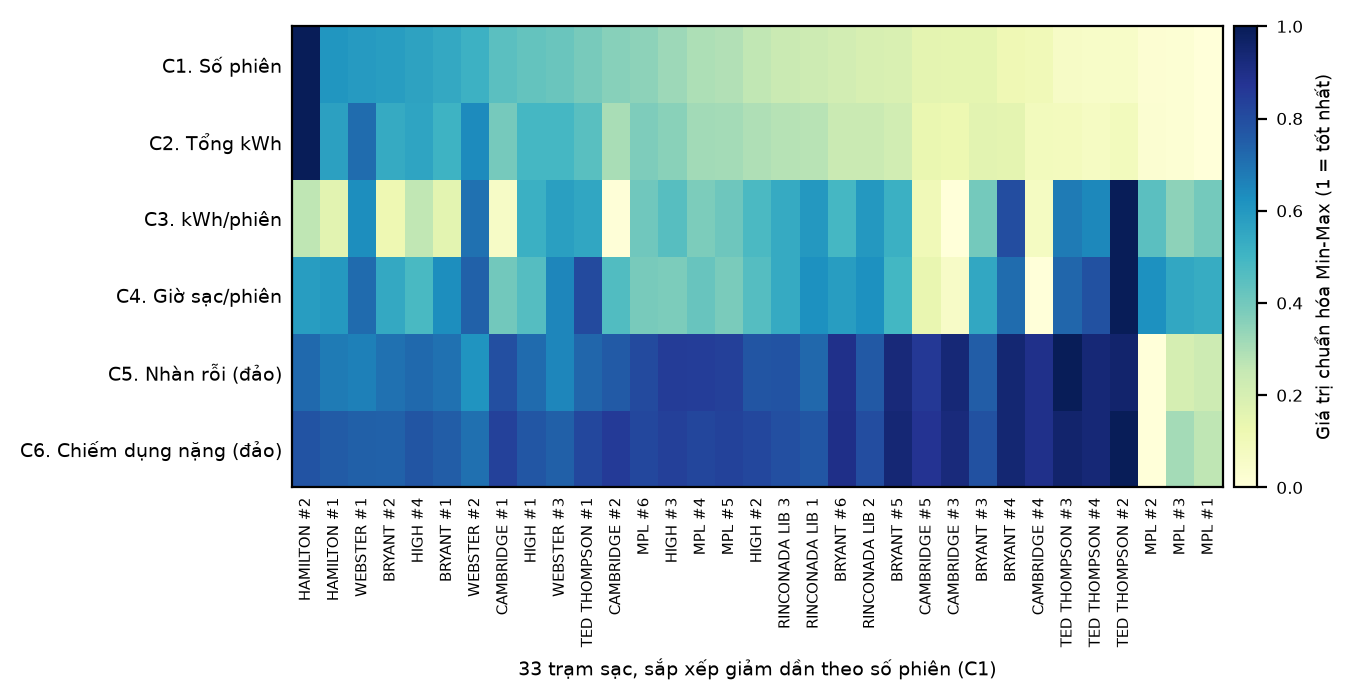

In [6]:
def chuan_hoa_minmax(X, tieu_chi):
    R = pd.DataFrame(index=X.index, columns=X.columns, dtype=float)
    for cot in X.columns:
        gia_tri = X[cot].astype(float)
        nho_nhat, lon_nhat = gia_tri.min(), gia_tri.max()
        if lon_nhat == nho_nhat:
            R[cot] = 1.0
            continue
        do_rong = lon_nhat - nho_nhat
        if tieu_chi[cot][2] > 0:
            R[cot] = (gia_tri - nho_nhat) / do_rong
        else:
            R[cot] = (lon_nhat - gia_tri) / do_rong
    return R


R = chuan_hoa_minmax(X, TIEU_CHI)
print("Khoảng giá trị sau chuẩn hóa:", f"[{R.to_numpy().min():.4f}, {R.to_numpy().max():.4f}]")
display(R.head(8))

ma_nhan = [c.split("_")[0] for c in R.columns]
ten_tram = [s.replace("PALO ALTO CA / ", "") for s in R.index]

fig, ax = plt.subplots(figsize=(7.2, 3.6), dpi=200)
im = ax.imshow(R.values.T, aspect="auto", cmap="YlGnBu", vmin=0, vmax=1)
ax.set_yticks(range(len(R.columns)))
ax.set_yticklabels([f"{a}. {TEN_NGAN[a]}" for a in ma_nhan], fontsize=7)
ax.set_xticks(range(len(ten_tram)))
ax.set_xticklabels(ten_tram, rotation=90, fontsize=5.5)
ax.set_xlabel("33 trạm sạc, sắp xếp giảm dần theo số phiên (C1)", fontsize=7)
cb = fig.colorbar(im, ax=ax, pad=0.01)
cb.set_label("Giá trị chuẩn hóa Min-Max (1 = tốt nhất)", fontsize=6.5)
cb.ax.tick_params(labelsize=6)
ax.tick_params(length=0)
fig.tight_layout()
fig.savefig(f"{THU_MUC_XUAT}/hinh_3_5_ma_tran_chuan_hoa.png", bbox_inches="tight")


### 5.1. Kiểm tra mức độ nén của phép chuẩn hóa

Min-Max kéo giãn theo giá trị lớn nhất, nên nếu một trạm có giá trị ngoại lai rất lớn thì các trạm còn lại bị nén
về sát 0. Bảng dưới đây đo tỷ lệ trạm nằm trong 10% đầu và 10% cuối của thang đo sau chuẩn hóa.


In [7]:
do_nen = pd.DataFrame({
    "Tỷ lệ trạm < 0,1": (R < 0.1).mean(),
    "Tỷ lệ trạm > 0,9": (R > 0.9).mean(),
    "Giá trị lớn nhất / trung vị (dữ liệu thô)": X.max() / X.median().replace(0, np.nan),
}).round(4)
do_nen


,"Tỷ lệ trạm < 0,1","Tỷ lệ trạm > 0,9",Giá trị lớn nhất / trung vị (dữ liệu thô)
C1_so_phien,0.1818,0.0303,3.4214
C2_tong_dien_nang,0.2121,0.0303,3.0744
C3_dien_nang_moi_phien,0.1212,0.0303,1.2652
C4_gio_sac_moi_phien,0.0606,0.0303,1.1912
C5_ty_le_nhan_roi,0.0303,0.1818,2.1554
C6_ty_le_chiem_dung_nghiem_trong,0.0303,0.1818,3.8801


## 6. Trọng số Entropy

Phương pháp Entropy gán trọng số lớn cho tiêu chí có mức độ phân tán cao, vì tiêu chí đó phân biệt các trạm rõ hơn.
Quy trình gồm bốn bước: tính tỷ trọng, tính entropy, tính độ phân kỳ và chuẩn hóa độ phân kỳ thành trọng số.
Áp dụng quy ước 0 × ln(0) = 0 cho các ô có tỷ trọng bằng 0.


,Entropy (e_j),Độ phân kỳ (d_j = 1 - e_j),Trọng số Entropy (w_j),Tên tiêu chí
Tiêu chí,,,,
C1_so_phien,0.9205,0.0795,0.2939,Số phiên sạc
C2_tong_dien_nang,0.9250,0.0750,0.2772,Tổng điện năng
C3_dien_nang_moi_phien,0.9437,0.0563,0.2078,Điện năng bình quân mỗi phiên
C4_gio_sac_moi_phien,0.9730,0.0270,0.0997,Thời gian sạc hữu ích bình quân
C5_ty_le_nhan_roi,0.9822,0.0178,0.0656,Tỷ lệ chiếm dụng nhàn rỗi
C6_ty_le_chiem_dung_nghiem_trong,0.9849,0.0151,0.0557,Tỷ lệ phiên chiếm dụng nghiêm trọng


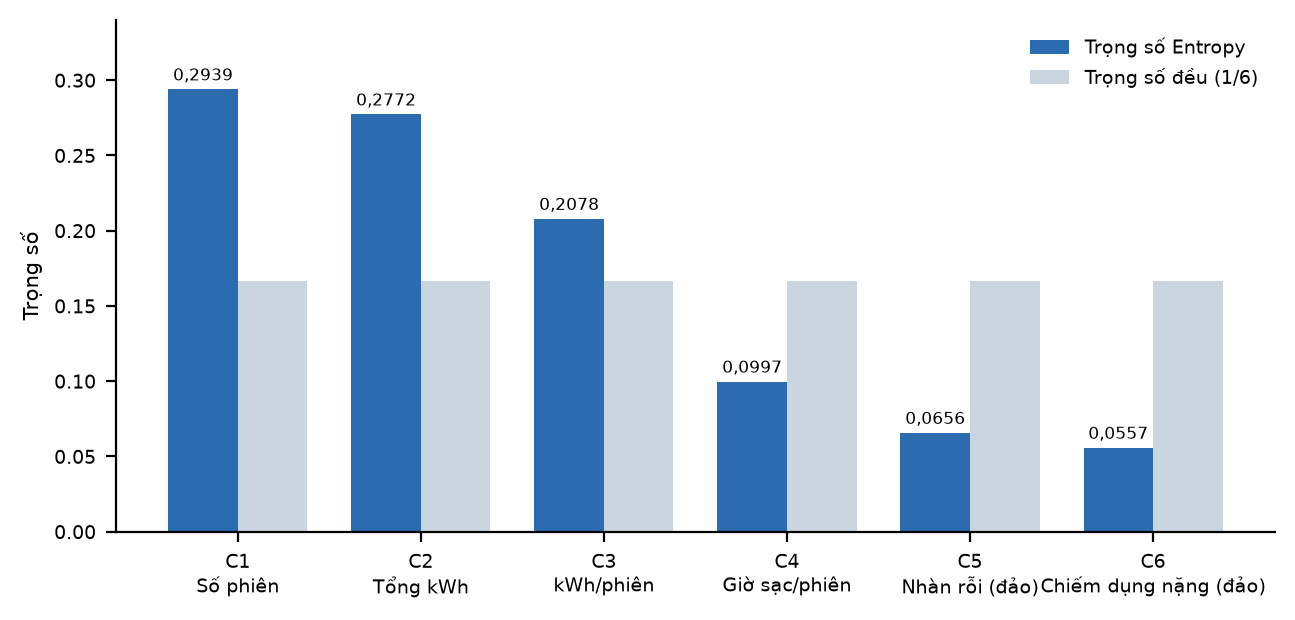

In [8]:
def trong_so_entropy(R):
    m = len(R)
    he_so_k = 1.0 / np.log(m)
    ket_qua = []

    for cot in R.columns:
        p = R[cot].to_numpy(dtype=float)
        tong = p.sum()
        p = np.full(m, 1.0 / m) if tong == 0 else p / tong
        # quy ước 0 x ln(0) = 0
        entropy = -he_so_k * np.sum(np.where(p > 0, p * np.log(np.where(p > 0, p, 1.0)), 0.0))
        ket_qua.append({"Tiêu chí": cot, "Entropy (e_j)": entropy, "Độ phân kỳ (d_j = 1 - e_j)": 1 - entropy})

    bang = pd.DataFrame(ket_qua).set_index("Tiêu chí")
    bang["Trọng số Entropy (w_j)"] = bang["Độ phân kỳ (d_j = 1 - e_j)"] / bang["Độ phân kỳ (d_j = 1 - e_j)"].sum()
    bang["Tên tiêu chí"] = [TIEU_CHI[c][0] for c in bang.index]
    return bang


bang_entropy = trong_so_entropy(R)
display(bang_entropy.round(6))

x = np.arange(len(bang_entropy))
w = 0.38
deu = np.full(len(bang_entropy), 1 / len(bang_entropy))

fig, ax = plt.subplots(figsize=(6.6, 3.2), dpi=200)
ax.bar(x - w / 2, bang_entropy["Trọng số Entropy (w_j)"], w, label="Trọng số Entropy", color="#2b6cb0")
ax.bar(x + w / 2, deu, w, label="Trọng số đều (1/6)", color="#cbd5e0")
for i, v in enumerate(bang_entropy["Trọng số Entropy (w_j)"]):
    ax.text(i - w / 2, v + 0.006, f"{v:.4f}".replace(".", ","), ha="center", fontsize=6)
ax.set_xticks(x)
ax.set_xticklabels([f"{a}\n{TEN_NGAN[a]}" for a in ma_nhan], fontsize=6.5)
ax.set_ylabel("Trọng số", fontsize=7.5)
ax.set_ylim(0, 0.34)
ax.legend(fontsize=7, frameon=False)
ax.spines[["top", "right"]].set_visible(False)
ax.tick_params(labelsize=7)
fig.tight_layout()
fig.savefig(f"{THU_MUC_XUAT}/hinh_3_6_trong_so.png", bbox_inches="tight")


## 7. Trọng số đều (Equal Weighting)

Trọng số đều gán cùng một giá trị 1/n cho mọi tiêu chí. Bộ trọng số này dùng làm đối chứng: nếu thứ hạng
không đổi nhiều khi chuyển từ trọng số Entropy sang trọng số đều thì kết luận xếp hạng ít phụ thuộc vào cách gán trọng số.


In [9]:
n = R.shape[1]
trong_so_deu = pd.Series(1.0 / n, index=R.columns, name="Trọng số đều (w_j)")
trong_so_deu.round(6)


C1_so_phien                        0.1667
C2_tong_dien_nang                  0.1667
C3_dien_nang_moi_phien             0.1667
C4_gio_sac_moi_phien               0.1667
C5_ty_le_nhan_roi                  0.1667
C6_ty_le_chiem_dung_nghiem_trong   0.1667
Name: Trọng số đều (w_j), dtype: float64

## 8. So sánh hai bộ trọng số

Bảng so sánh cho thấy tiêu chí nào được Entropy đánh giá quan trọng hơn hoặc thấp hơn so với giả định cân bằng.
Chênh lệch tuyệt đối lớn cho biết kết quả xếp hạng ở bước sau nhạy cảm với cách chọn trọng số.


In [10]:
so_sanh = bang_entropy[["Tên tiêu chí", "Entropy (e_j)", "Trọng số Entropy (w_j)"]].copy()
so_sanh["Trọng số đều (w_j)"] = trong_so_deu
so_sanh["Chênh lệch"] = so_sanh["Trọng số Entropy (w_j)"] - so_sanh["Trọng số đều (w_j)"]
so_sanh["Tỷ lệ so với trọng số đều"] = so_sanh["Trọng số Entropy (w_j)"] * len(R.columns)
so_sanh = so_sanh.round(6)

X.round(6).to_csv(f"{THU_MUC_XUAT}/ma_tran_tieu_chi_tho.csv", encoding="utf-8-sig")
R.round(6).to_csv(f"{THU_MUC_XUAT}/ma_tran_chuan_hoa_minmax.csv", encoding="utf-8-sig")
so_sanh.to_csv(f"{THU_MUC_XUAT}/so_sanh_trong_so.csv", encoding="utf-8-sig")
nhat_ky.to_csv(f"{THU_MUC_XUAT}/nhat_ky_lam_sach.csv", index=False, encoding="utf-8-sig")
so_sanh


,Tên tiêu chí,Entropy (e_j),Trọng số Entropy (w_j),Trọng số đều (w_j),Chênh lệch,Tỷ lệ so với trọng số đều
Tiêu chí,,,,,,
C1_so_phien,Số phiên sạc,0.9205,0.2939,0.1667,0.1272,1.7633
C2_tong_dien_nang,Tổng điện năng,0.9250,0.2772,0.1667,0.1106,1.6634
C3_dien_nang_moi_phien,Điện năng bình quân mỗi phiên,0.9437,0.2078,0.1667,0.0412,1.2470
C4_gio_sac_moi_phien,Thời gian sạc hữu ích bình quân,0.9730,0.0997,0.1667,-0.0670,0.5982
C5_ty_le_nhan_roi,Tỷ lệ chiếm dụng nhàn rỗi,0.9822,0.0656,0.1667,-0.1010,0.3937
C6_ty_le_chiem_dung_nghiem_trong,Tỷ lệ phiên chiếm dụng nghiêm trọng,0.9849,0.0557,0.1667,-0.1110,0.3343
